In [1]:
import geopandas as gpd
import shapely
import shapely.geometry as sg
import numpy as np
import pandas as pd
import geemap
import ee
# ee.Authenticate()
# ee.Initialize()
import json

In [2]:
gdf=gpd.read_file('jaipur_crops_rough.shp').to_crs(7755)

<Axes: >

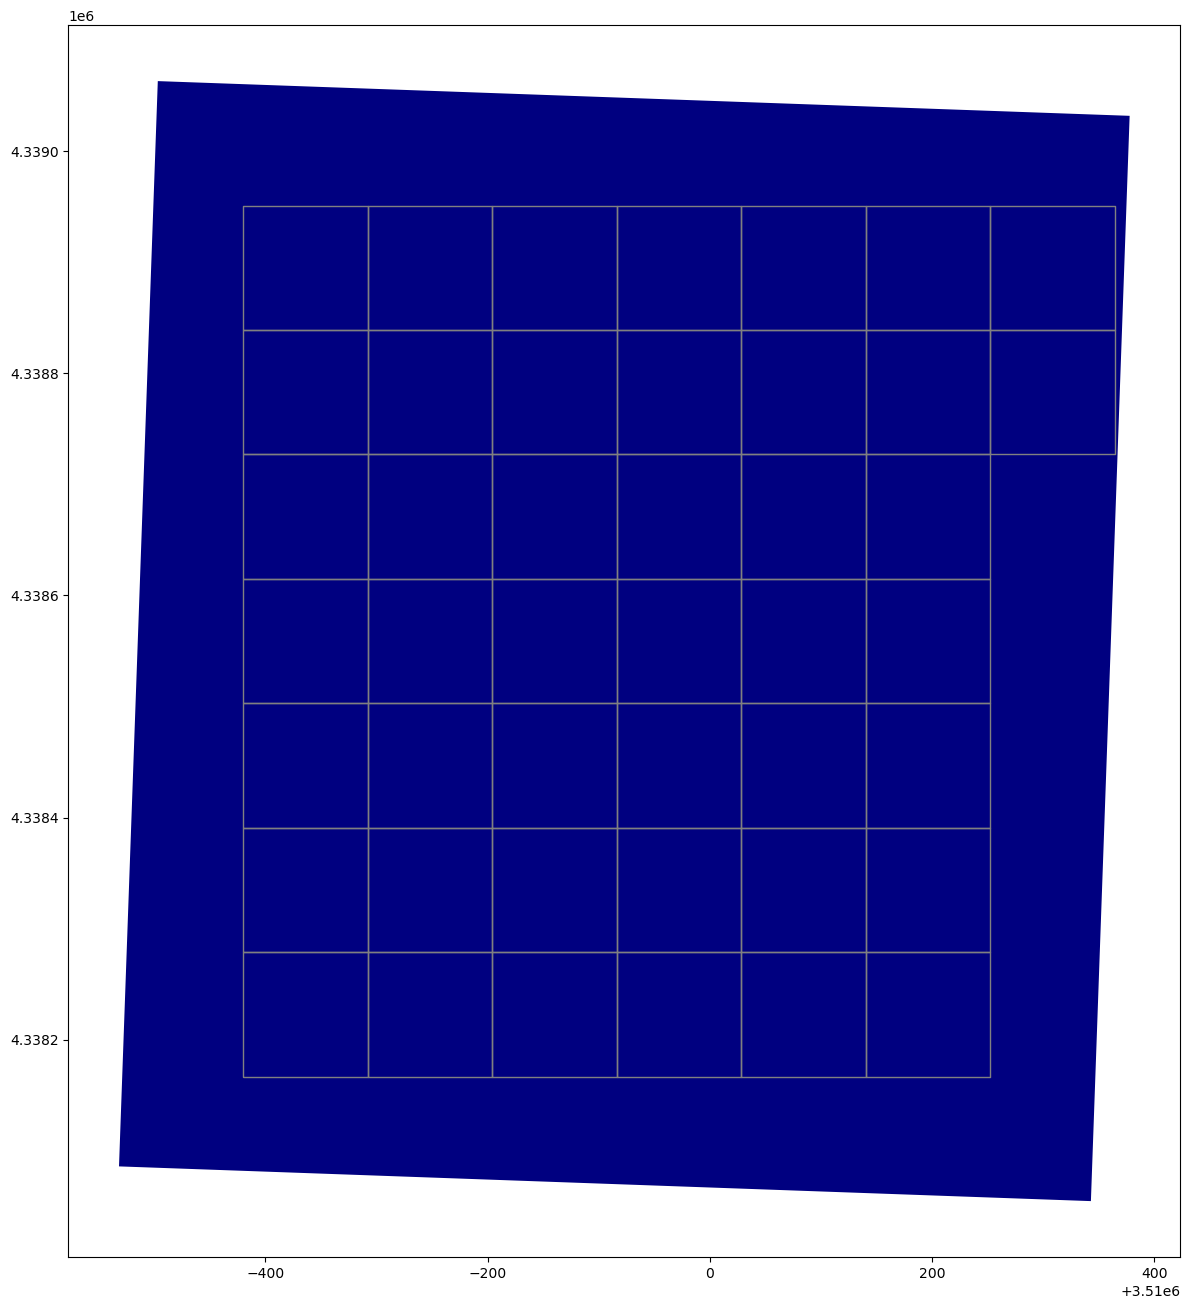

In [3]:
i=0
region=gdf[i:i+1]

ax = region.plot(markersize=.1, figsize=(16, 16), cmap='jet')

xmin, ymin, xmax, ymax= region.total_bounds

## real cell dimensions
cell_width  = 112
cell_height = 112

grid_cells = []
for x0 in np.arange(xmin, xmax+cell_width, cell_width ):
    for y0 in np.arange(ymin, ymax+cell_height, cell_height):
        x1 = x0-cell_width
        y1 = y0+cell_height
        new_cell = shapely.geometry.box(x0, y0, x1, y1)
        if new_cell.intersects(region['geometry'].values[0]):
            grid_cells.append(new_cell)
        else:
            pass
        
grid_cells=[grid_cells[i] for i in range(len(grid_cells)) if region.geometry.values[0].contains(grid_cells[i])]      
cell_df = gpd.GeoDataFrame(grid_cells, columns=['geometry'])
cell_df.plot(ax=ax,facecolor="none", edgecolor='grey')



In [10]:
# all_cells=gpd.GeoDataFrame()

# for i in range(len(gdf)):
#     # print(f'{i+1}/{len(gdf)}')
#     region=gdf[i:i+1]
#     xmin, ymin, xmax, ymax= region.total_bounds

#     ## real cell dimensions
#     cell_width  = 112
#     cell_height = 112

#     grid_cells = []
#     for x0 in np.arange(xmin, xmax+cell_width, cell_width ):
#         for y0 in np.arange(ymin, ymax+cell_height, cell_height):
#             x1 = x0-cell_width
#             y1 = y0+cell_height
#             new_cell = shapely.geometry.box(x0, y0, x1, y1)
#             if new_cell.intersects(region['geometry'].values[0]):
#                 grid_cells.append(new_cell)
#             else:
#                 pass

#     grid_cells=[grid_cells[i] for i in range(len(grid_cells)) if region.geometry.values[0].contains(grid_cells[i])]      
#     cell_df = gpd.GeoDataFrame(grid_cells, columns=['geometry'])
#     all_cells=pd.concat([all_cells, cell_df])
# all_cells.crs=region.crs  

# all_cells.to_file('jaipur_crops_tiles.shp')


In [4]:
all_cells=gpd.read_file('jaipur_crops_tiles.shp')

In [31]:
# random_index=np.random.uniform(0,len(all_cells), 500)
# random_cells= all_cells.iloc[random_index].reset_index()
# random_cells.to_file('jaipur_500_tiles.shp')

In [5]:
random_cells=gpd.read_file('jaipur_500_tiles.shp')

In [6]:
random_cells.explore()

In [7]:
#create empty map
Map = geemap.Map()

Map

Map(center=[20, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=HBox(children=(Togg…

In [233]:
# hand print loop
i=201
roi= ee.Feature(json.loads(random_cells[i:i+1].to_crs(4326).to_json())['features'][0]['geometry'])

# center map on selected country
Map.centerObject(roi, 18)

landcover= ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1").filterDate("2015-01-1","2023-05-19").filterBounds(roi.geometry()).select('label')
crop_class = 4
# Create a binary layer where 1 represents crop and 0 represents all other landcover types
landcover_crop = landcover.map(lambda image: image.eq(crop_class))

# Define the visualization parameters for the crop layer
cropVis = { "min":0, "max":1, 'palette': ['black', '#E49635']}

# Add the crop layer to the map
Map.addLayer(landcover_crop.mosaic().clip(roi.geometry()).selfMask(), cropVis, "Crop Landcover")


drawing=ee.FeatureCollection([roi]).draw(color= '800080', pointRadius= 5, strokeWidth= 2)
Map.addLayer(drawing, opacity=0.2)



In [234]:
random_keep=[0,2,3,4,6,8,9,11,12,13,14,15,16,17,18,20,21,22,23,25,27,28,29,33,37,38,40,43,44,49,53,55,58,62,63,65,66,67,68,70,71,73,74,75,78,82,84,87,89,90,91,92,94,95,97,98,106,108,109,111,114,115,116,120,122,123,126,130,134,135,136,137,148,150,151,161,162,163,166,169,170,171,175,177,180,181,182,185,186,188,189,190,193,194,195,196,197,198,199,201]
len(random_keep)

100

In [235]:
random_cells.iloc[random_keep].to_file('jaipur_100_tiles.shp')